# Linear Regression with Ridge and Lasso

- **Ridge regression** applies L2 regularization and reduces the size of model coefficients.
- **Lasso regression** applies L1 regularization and can reduce unimportant coefficients to zero.


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from kagglehub import KaggleDatasetAdapter
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [20]:
# Load the employee salary dataset used in the original lab.
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "anninasimon/employee-salary-dataset",
    "Employee_Salary_Dataset.csv",
)

df.head()

Using Colab cache for faster access to the 'employee-salary-dataset' dataset.


,ID,Experience_Years,Age,Gender,Salary
0,1,5,28,Female,250000
1,2,1,21,Male,50000
2,3,3,23,Female,170000
3,4,2,22,Male,25000
4,5,1,17,Male,10000


In [21]:
# ID is an identifier, not a useful predictor. Keep the employee attributes as features.
features = ["Experience_Years", "Age", "Gender"]
target = "Salary"

X = df[features]
y = np.log1p(df[target])
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)
numeric_features = ["Experience_Years", "Age"]
categorical_features = ["Gender"]
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            categorical_features,
        ),
    ]
)

In [22]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000),
}

def make_model(regressor):
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", regressor),
        ]
    )

def evaluate_model(name, regressor):
    model = make_model(regressor)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)

    return {
        "Model": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, predictions),
        "model": model,
        "predictions": predictions,
    }

results = [
    evaluate_model(name, regressor)
    for name, regressor in models.items()
]

results_table = pd.DataFrame(
    [{key: result[key] for key in ("Model", "MSE", "RMSE", "R2")} for result in results]
).set_index("Model")
results_table.round(4)

,MSE,RMSE,R2
Model,,,
Linear Regression,2.1326,1.4603,0.2609
Ridge,2.2205,1.4902,0.2304
Lasso,2.1415,1.4634,0.2578


In [23]:
# Compare actual and predicted log salaries for each model.
comparison = pd.DataFrame({"Actual log salary": y_test.reset_index(drop=True)})
for result in results:
    comparison[result["Model"]] = result["predictions"]

comparison.head(10)

,Actual log salary,Linear Regression,Ridge,Lasso
0,8.006701,10.509247,10.543013,10.502189
1,12.301842,13.453940,13.395526,13.428170
2,9.093919,10.705552,10.810142,10.738316
3,10.126671,11.520544,11.508383,11.507398
4,11.373675,11.070949,11.123332,11.102359
5,8.716208,10.335851,10.427553,10.371546
6,12.706851,12.995042,12.969339,12.971753


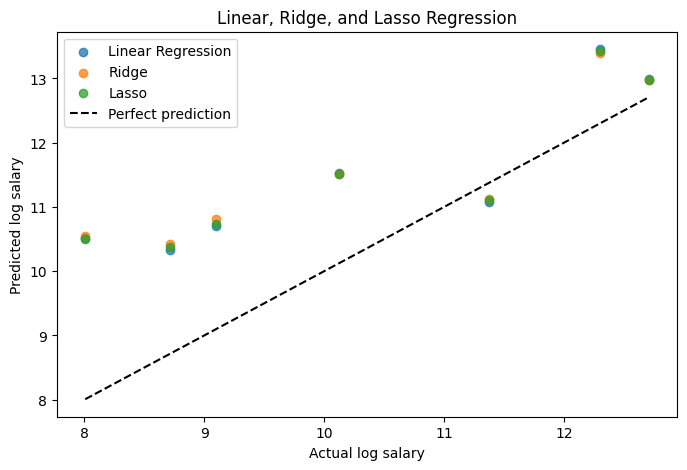

In [24]:
# Plot the test-set predictions. A perfect model would lie on the dashed line.
plt.figure(figsize=(8, 5))
for result in results:
    plt.scatter(
        y_test,
        result["predictions"],
        label=result["Model"],
        alpha=0.75,
    )

limits = [y_test.min(), y_test.max()]
plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Actual log salary")
plt.ylabel("Predicted log salary")
plt.title("Linear, Ridge, and Lasso Regression")
plt.legend()
plt.show()